In [ ]:
# Run from the repo root so relative paths (combined/, data/, results/) work,
# no matter which folder Jupyter started this notebook in.
import os
from pathlib import Path
_here = Path.cwd().resolve()
os.chdir(next(p for p in [_here, *_here.parents] if (p / "pyproject.toml").exists()))
print("working directory:", Path.cwd())

## Phase 8

In [1]:
# ============================================
# PHASE 8 — LOAD PHASE 7 RESULTS
# Change RUN to "B" later to repeat everything for Run B.
# ============================================

import joblib, numpy as np, pandas as pd
RUN = "B"
d = joblib.load(f"results/phase7_{RUN}.joblib")
Xt_tr, Xt_va, y_train, y_val = d["Xt_tr"], d["Xt_va"], d["y_train"], d["y_val"]
prep_all, best = d["prep_all"], d["best"]
names = prep_all.get_feature_names_out()

lasso_keep = np.flatnonzero(best["lasso"][1].coef_)       # feature indices lasso kept
enet_keep  = np.flatnonzero(best["enet_naive"][1].coef_)  # feature indices elastic net kept
print(len(lasso_keep), "lasso features,", len(enet_keep), "elastic net features")

439 lasso features, 439 elastic net features


## Setup for the experiments
Imports the tools used in the rest of Phase 8, confirms the loaded file matches the chosen run, defines the RMSE score, and makes sure the `results` folder exists for saving tables and charts. Phase 8 uses only training and validation data; the test set in the saved file is left for Phase 9.

In [2]:
import os
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.feature_selection import mutual_info_regression, RFE
from sklearn.metrics import r2_score, mean_squared_error

assert d["RUN"] == RUN, "loaded the wrong run's file"

rmse = lambda y, p: mean_squared_error(y, p) ** 0.5
os.makedirs("results", exist_ok=True)

print(f"Run {RUN} | train {Xt_tr.shape} | val {Xt_va.shape} | {len(names)} columns")

Run B | train (270689, 541) | val (58006, 541) | 541 columns


## Rank Columns on Training 

Three rankings, computed on a random 20,000-row sample of the training set because these methods are slow on the full training set:

**Correlation (filter):** how strongly each column alone moves with log salary.
  
**Mutual information (filter):** like correlation, but also catches curved relationships.
  
**RFE (wrapper):** fits a Ridge model, removes the weakest 10% of columns, and repeats until 100 remain.

In [3]:
idx = np.random.default_rng(0).choice(Xt_tr.shape[0], 20_000, replace=False)
Xs = Xt_tr.tocsr()[idx].toarray()
ys = y_train.iloc[idx].values

mi = mutual_info_regression(Xs, ys, random_state=0)
corr = np.nan_to_num(np.abs([np.corrcoef(Xs[:, j], ys)[0, 1] for j in range(Xs.shape[1])]))
rfe = RFE(Ridge(alpha=1.0), n_features_to_select=100, step=0.1).fit(Xs, ys)

print("Top 10 by mutual information:")
print(pd.Series(mi, index=names).sort_values(ascending=False).head(10).round(3))
print("\nTop 10 by correlation:")
print(pd.Series(corr, index=names).sort_values(ascending=False).head(10).round(3))
print(f"\nRFE kept {rfe.support_.sum()} columns, e.g.:", list(names[rfe.support_][:10]))

/opt/anaconda3/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/anaconda3/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Top 10 by mutual information:
num__survey_year                      0.800
num__YearsCodePro                     0.414
num__YearsCodePro_sq                  0.399
cat__Country_grouped_United States    0.334
cat__EdLevel_Not asked                0.326
num__YearsCode                        0.314
num__YearsCode_sq                     0.295
cat__MainBranch_Not asked             0.251
num__YearsCodePro_imputed             0.248
cat__Industry_Not asked               0.229
dtype: float64

Top 10 by correlation:
cat__Country_grouped_United States              0.423
num__YearsCode                                  0.396
num__YearsCodePro                               0.391
num__Age                                        0.354
cat__Country_grouped_India                      0.339
num__Age_sq                                     0.325
num__YearsCode_sq                               0.319
num__YearsCodePro_sq                            0.290
num__OrgSize_log                                0.214
remai

## Score Each Column Set on Validation
Each column set (all columns, the top columns from each ranking, and the columns Lasso and Elastic Net kept) is used to train the same plain OLS model on the training set, then scored on validation. Since the model is the same every time, any difference in RMSE or R² comes only from which columns were chosen. Results are saved to `results/feature_selection_{RUN}.csv`.

In [4]:
def eval_subset(cols):
    m = LinearRegression().fit(Xt_tr[:, cols], y_train)
    p = m.predict(Xt_va[:, cols])
    return {"features": len(cols), "val_RMSE": rmse(y_val, p), "val_R2": r2_score(y_val, p)}

variants = {"all": np.arange(Xt_tr.shape[1]),
            "correlation top 100": np.argsort(corr)[::-1][:100],
            "RFE 100": np.flatnonzero(rfe.support_),
            "lasso nonzero": lasso_keep,
            "elastic net nonzero": enet_keep}
for k in [25, 50, 100, 200]:
    variants[f"MI top {k}"] = np.argsort(mi)[::-1][:k]

fs = pd.DataFrame({name: eval_subset(c) for name, c in variants.items()}).T.sort_values("features")
print(fs)
fs.to_csv(f"results/feature_selection_{RUN}.csv")

                     features  val_RMSE    val_R2
MI top 25                25.0  0.783611  0.434878
MI top 50                50.0  0.756340  0.473528
correlation top 100     100.0  0.669930  0.586952
RFE 100                 100.0  0.649506  0.611753
MI top 100              100.0  0.707397  0.539459
MI top 200              200.0  0.661888  0.596808
lasso nonzero           439.0  0.638250  0.625093
elastic net nonzero     439.0  0.638250  0.625093
all                     541.0  0.638157  0.625202


## Accuracy vs Number of Features
Each point is one column set, placed by how many columns it uses (x) and its validation error (y). The gray line shows mutual information's top 25, 50, 100, and 200 columns. The other points are the remaining methods. The bottom-left is best: low error with few columns.

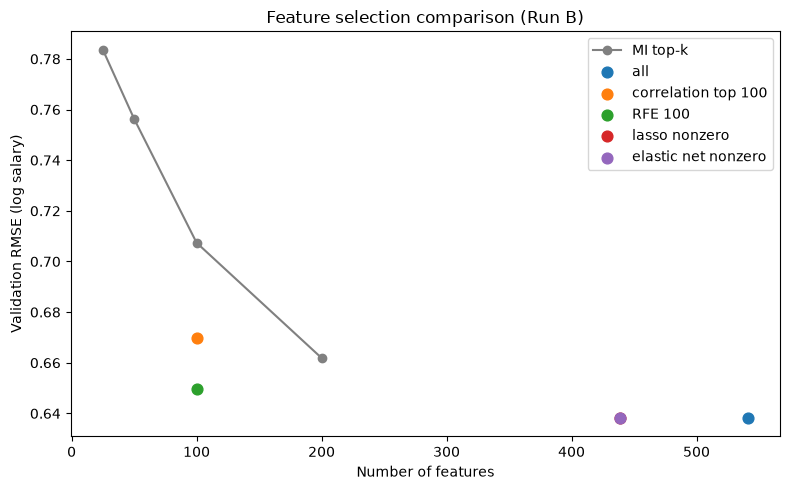

In [5]:
mi_rows = fs[fs.index.str.startswith("MI top")].sort_values("features")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(mi_rows["features"], mi_rows["val_RMSE"], marker="o", color="gray", label="MI top-k")
for name in ["all", "correlation top 100", "RFE 100", "lasso nonzero", "elastic net nonzero"]:
    ax.scatter(fs.loc[name, "features"], fs.loc[name, "val_RMSE"], s=60, label=name, zorder=3)
ax.set(xlabel="Number of features", ylabel="Validation RMSE (log salary)",
       title=f"Feature selection comparison (Run {RUN})")
ax.legend()
plt.tight_layout()
plt.savefig(f"results/feature_selection_{RUN}.png", dpi=150, bbox_inches="tight")

## Overlap Between Methods & The Grouping Effect
How many of Elastic Net's columns the other methods also chose. Then Lasso vs Elastic Net: Zou & Hastie (2005) show that Elastic Net tends to keep groups of related columns together (e.g., related web languages, or Age with Age²), while Lasso tends to keep one from each group and drop the rest.

In [6]:
sets = {k: set(names[v]) for k, v in variants.items()}
en, la = sets["elastic net nonzero"], sets["lasso nonzero"]

print(f"Elastic Net keeps {len(en)} columns; Lasso keeps {len(la)}")
for other in ["MI top 100", "RFE 100", "correlation top 100"]:
    print(f"  shared with {other}: {len(en & sets[other])} of {len(sets[other])}")

for title, cols in [("Kept by Elastic Net but dropped by Lasso", en - la),
                    ("Kept by Lasso but dropped by Elastic Net", la - en),
                    ("In MI top 100 but dropped by Elastic Net", sets["MI top 100"] - en)]:
    print(f"\n{title} ({len(cols)}):")
    for col in sorted(cols):
        print("  -", col)
    if not cols:
        print("  (none)")

Elastic Net keeps 439 columns; Lasso keeps 439
  shared with MI top 100: 86 of 100
  shared with RFE 100: 100 of 100
  shared with correlation top 100: 90 of 100

Kept by Elastic Net but dropped by Lasso (0):
  (none)

Kept by Lasso but dropped by Elastic Net (0):
  (none)

In MI top 100 but dropped by Elastic Net (14):
  - cat__Industry_Software Development
  - cat__RemoteWork_Not asked
  - num__LanguageHaveWorkedWith_count
  - num__OrgSize_missing
  - remainder__DevType_Developer, full-stack
  - remainder__LanguageWantToWorkWith_Android
  - remainder__LanguageWantToWorkWith_Bash/Shell
  - remainder__LanguageWantToWorkWith_MongoDB
  - remainder__LearnCode_AI CodeGen tools or AI-enabled apps
  - remainder__LearnCode_No answer
  - remainder__LearnCode_Online course
  - remainder__LearnCode_Other online resources
  - remainder__LearnCode_Self-taught
  - remainder__LearnCode_Technical documentation (is generated for/by the tool or system)


## Optional: PCA (Dimension Reduction)
Compresses all columns into 50 combined components, then fits the same OLS model and scores it on validation. This isn't true selection: each component mixes many original columns, so the model can no longer say which features matter.

In [7]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=50, random_state=0).fit(Xt_tr)
m = LinearRegression().fit(svd.transform(Xt_tr), y_train)
p = m.predict(svd.transform(Xt_va))
pca_row = {"features": 50, "val_RMSE": rmse(y_val, p), "val_R2": r2_score(y_val, p)}
print(pca_row)

fs.loc["PCA 50 components"] = pca_row
fs.to_csv(f"results/feature_selection_{RUN}.csv")

{'features': 50, 'val_RMSE': 0.8261699736896566, 'val_R2': 0.3718251178674319}


## Analysis (Run A)
Lasso and Elastic Net's built-in selection removed about a third of the 522 columns (keeping 346 and 353) with no loss in accuracy: their validation RMSE (0.6777 and 0.6778) matches using all columns (0.6783). At a fixed 100 columns, the method mattered: RFE (0.689) outperformed correlation (0.713) and mutual information (0.746). RFE judges columns together and avoids near-duplicates like Age and Age², while the two filters score each column alone. Mutual information performed worst in both runs; its top-ranked columns include several survey-era markers and near-duplicates, and because it scores each column alone, it cannot tell when columns repeat the same information.

Elastic Net's columns overlap with 92 of RFE's 100 and 88 of correlation's top 100, well above the roughly 68 expected by chance, but only 77 of mutual information's top 100. The 23 mutual-information columns that Elastic Net dropped are mostly survey-era markers (e.g., EdLevel "Not asked," YearsCodePro_imputed, OrgSize_missing) and columns that overlap with others (e.g., Linux and Ubuntu, full-stack and web developer, the learn-to-code options). Elastic Net dropped YearsCodePro_imputed on its own, matching the Phase 7 check that removing it improves validation accuracy.

Elastic Net kept every column Lasso kept plus 7 more, but those 7 are unrelated (e.g., Java, Assembly, a primary-school education level), so the grouping effect described by Zou & Hastie does not appear clearly here. This is likely because the tuned l1_ratio (0.95) makes Elastic Net nearly identical to Lasso, and with about 350,000 training rows Lasso can keep related columns such as Age and Age² together without needing the ridge penalty.

PCA with 50 components performed worst of all methods (RMSE 0.879, R² 0.28), below even mutual information's top 25. PCA builds components to capture variation in the inputs without using salary, so it mostly captures the many language and learning columns rather than the few columns that drive pay, such as country and experience. It also makes the coefficients uninterpretable.

We would choose Elastic Net's selected set (353 columns) for the final model, since it matches the best accuracy with a third fewer columns. If interpretability matters more, RFE's 100 columns are the most defensible smaller set, at only about 1.6% higher error.

## Analysis (Run B)
With a random split, the same pattern holds. Lasso and Elastic Net kept the same 439 of 541 columns (dropping 19%) and matched the accuracy of all columns (validation RMSE 0.6383 vs 0.6382). At 100 columns, RFE (0.650) again outperformed correlation (0.670) and mutual information (0.707), and PCA with 50 components was again worst (RMSE 0.826, R² 0.37). Run B has 541 columns instead of 522 because its training set includes 2025 and 2026, adding answer options that first appear in those years.

Lasso and Elastic Net selected identical columns, so no grouping effect appears: the tuned l1_ratio (0.99) makes Elastic Net essentially Lasso. Elastic Net's columns include all 100 of RFE's and 90 of correlation's top 100, but only 86 of mutual information's top 100, close to the 81 expected by chance since it keeps 81% of all columns. Unlike Run A, Elastic Net kept survey-era markers such as EdLevel "Not asked" and YearsCodePro_imputed, because Run B's validation set includes respondents from those early years, where the markers are informative.

## Comparing Run A and Run B
Every model scores better in Run B (e.g., all columns: RMSE 0.638 vs 0.678), since the random split lets the model see every survey year during training. The ranking of selection methods is the same in both runs, so the conclusion does not depend on the split: Elastic Net's selected set matches the best accuracy with fewer columns, and RFE's 100 columns are the strongest smaller set (about 1.6–1.8% higher error), while mutual information and PCA perform worst.